# Week 1 EDA — MSME Lending Portfolio Analytics

**Project:** Portfolio project built on the Home Credit Default Risk
dataset (Kaggle), used as a proxy for MSME lending analytics. combining skills in SQL reporting, credit analysis, segmentation and documentation).


**Read alongside:** `docs/metrics_definitions.md` — every metric here
(DPD, PAR30/60/90, utilization ratio) is defined there in full, including
the key caveat that PAR in this project is an *ever-delinquent,
amount-proxied* estimate, not a true point-in-time figure, since the
dataset has no outstanding-principal field.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

ACCENT = "#2f7a5c"
AMBER = "#9c7325"


## Connect to PostgreSQL

In [2]:
import os
from dotenv import load_dotenv
from sqlalchemy.engine import URL

load_dotenv(override=True)  # reads variables from a .env file in the project root

DB_USER = os.environ.get("DB_USER")
DB_PASS = os.environ.get("DB_PASS")
DB_HOST = os.environ.get("DB_HOST", "localhost")
DB_PORT = os.environ.get("DB_PORT", "5432")
DB_NAME = os.environ.get("DB_NAME")

# URL.create() builds the connection string safely, escaping special
# characters in the password (e.g. @, :, /) automatically. An f-string
# here would silently break on a password containing "@", since that
# character is also the separator between credentials and host.
connection_url = URL.create(
    drivername="postgresql+psycopg2",
    username=DB_USER,
    password=DB_PASS,
    host=DB_HOST,
    port=int(DB_PORT),
    database=DB_NAME,
)
engine = create_engine(connection_url)

# Target class balance

In [3]:
target_balance = pd.read_sql("""
    SELECT target, count(*) AS n
    FROM application_train
    GROUP BY target
    ORDER BY target;
""", engine)
target_balance["pct"] = (target_balance["n"] / target_balance["n"].sum() * 100).round(2)
target_balance

,target,n,pct
0,0,282686,91.93
1,1,24825,8.07


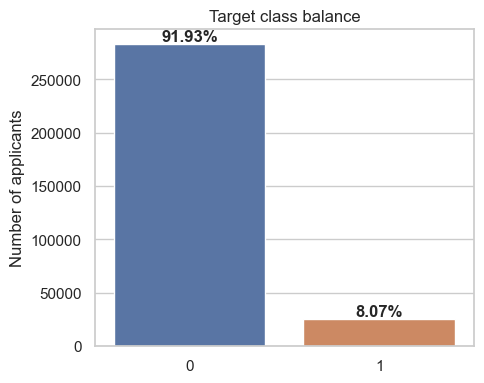

In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(data=target_balance, x="target", y="n", ax=ax, hue="target",legend=False)
#ax.set_xticklabels(["Repaid (0)", "Defaulted (1)"])
ax.set_ylabel("Number of applicants")
ax.set_xlabel("")
ax.set_title("Target class balance")
for i, row in target_balance.iterrows():
    ax.text(i, row["n"] + 3000, f"{row['pct']}%", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

**Finding:** the dataset is heavily imbalanced — roughly 92% non-defaults vs. 8%
defaulted. This has direct implications such as ;
- Plain accuracy would be meaningless here — a model predicting "never
  defaults" is already ~92% accurate and tells nothing useful.
- Therefore the project will use **KS, Gini, and PSI** rather
  than accuracy for the scorecard — these are built to handle class
  imbalance.


In [5]:
missing_query = """
SELECT
    round(count(*) FILTER (WHERE ext_source_1 IS NULL) * 100.0 / count(*), 1) AS ext_source_1,
    round(count(*) FILTER (WHERE ext_source_2 IS NULL) * 100.0 / count(*), 1) AS ext_source_2,
    round(count(*) FILTER (WHERE ext_source_3 IS NULL) * 100.0 / count(*), 1) AS ext_source_3,
    round(count(*) FILTER (WHERE occupation_type IS NULL) * 100.0 / count(*), 1) AS occupation_type,
    round(count(*) FILTER (WHERE own_car_age IS NULL) * 100.0 / count(*), 1) AS own_car_age,
    round(count(*) FILTER (WHERE name_type_suite IS NULL) * 100.0 / count(*), 1) AS name_type_suite
FROM application_train;
"""
missing = pd.read_sql(missing_query, engine).T.reset_index()
missing.columns = ["field", "pct_missing"]
missing = missing.sort_values("pct_missing", ascending=False)
missing

,field,pct_missing
4,own_car_age,66.00
0,ext_source_1,56.40
3,occupation_type,31.30
2,ext_source_3,19.80
5,name_type_suite,0.40
1,ext_source_2,0.20


**Finding:** `OWN_CAR_AGE` and `EXT_SOURCE_1` have the highest percenrage of missing values, followed by `OCCUPATION_TYPE`. The `EXT_SOURCE_*` fields are documented as among the strongest predictors in this dataset despite the gaps, so the project's scorecard needs a deliberate missing-value strategy for them (e.g. a dedicated "missing" WoE bin rather than mean imputation, which would discard the signal that missingness itself may carry).

## 3. Income distribution and outlier check

In [6]:
income_stats = pd.read_sql("""
    SELECT
        min(amt_income_total) AS min_income,
        max(amt_income_total) AS max_income,
        percentile_cont(0.5) WITHIN GROUP (ORDER BY amt_income_total) AS median_income,
        percentile_cont(0.99) WITHIN GROUP (ORDER BY amt_income_total) AS p99_income,
        count(*) FILTER (WHERE amt_income_total > 10000000) AS n_extreme_outliers
    FROM staging.stg_application;
""", engine)
income_stats

,min_income,max_income,median_income,p99_income,n_extreme_outliers
0,"25,650.00","117,000,000.00","147,150.00","472,500.00",3


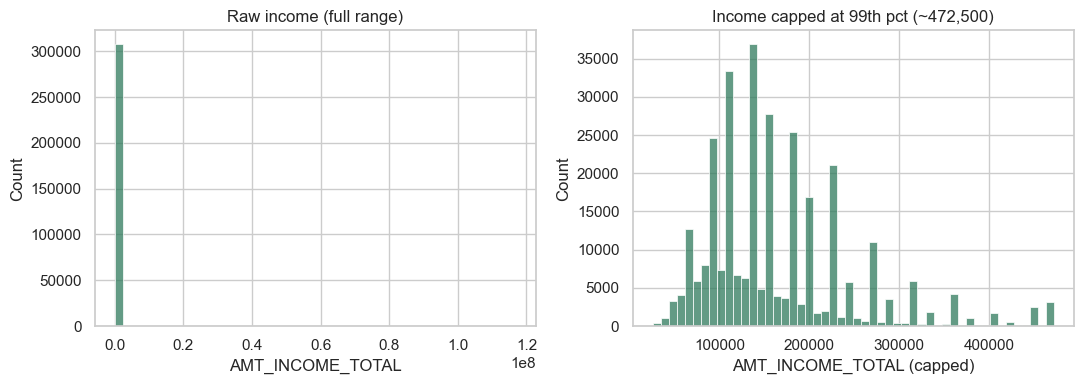

In [7]:
#Plotting it for better view and analysis
income_df = pd.read_sql("SELECT amt_income_total FROM staging.stg_application;", engine)
cap = income_df["amt_income_total"].quantile(0.99)
income_df["amt_income_capped"] = income_df["amt_income_total"].clip(upper=cap)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(income_df["amt_income_total"], bins=50, ax=axes[0], color=ACCENT)
axes[0].set_title("Raw income (full range)")
axes[0].set_xlabel("AMT_INCOME_TOTAL")

sns.histplot(income_df["amt_income_capped"], bins=50, ax=axes[1], color=ACCENT)
axes[1].set_title(f"Income capped at 99th pct (~{cap:,.0f})")
axes[1].set_xlabel("AMT_INCOME_TOTAL (capped)")
plt.tight_layout()
plt.show()

**Finding:** only 3 applicants (out of ~307,511) report income above
10,000,000. This is confirmed as an isolated artefact, not a genuine
distribution tail. This is how to handle it going forward:

- **Scorecard (WoE binning):** left unmodified. WoE groups values
  into bins rather than using raw magnitude, so the outlier is absorbed
  into the top bin without special handling.
- **Segmentation (k-means):** income will be capped at the 99th
  percentile before clustering, since k-means is distance-based and a
  single extreme value would otherwise distort cluster centers on its own.

 ## 4. Default rate by segment

In [8]:
#Default rates by education
by_education = pd.read_sql("""
    SELECT name_education_type, count(*) AS n, round(avg(target)*100, 2) AS default_rate_pct
    FROM staging.stg_application
    GROUP BY name_education_type
    ORDER BY default_rate_pct DESC;
""", engine)

by_family = pd.read_sql("""
    SELECT name_family_status, count(*) AS n, round(avg(target)*100, 2) AS default_rate_pct
    FROM staging.stg_application
    GROUP BY name_family_status
    ORDER BY default_rate_pct DESC;
""", engine)

by_education

,name_education_type,n,default_rate_pct
0,Lower secondary,3816,10.93
1,Secondary / secondary special,218391,8.94
2,Incomplete higher,10277,8.48
3,Higher education,74863,5.36
4,Academic degree,164,1.83


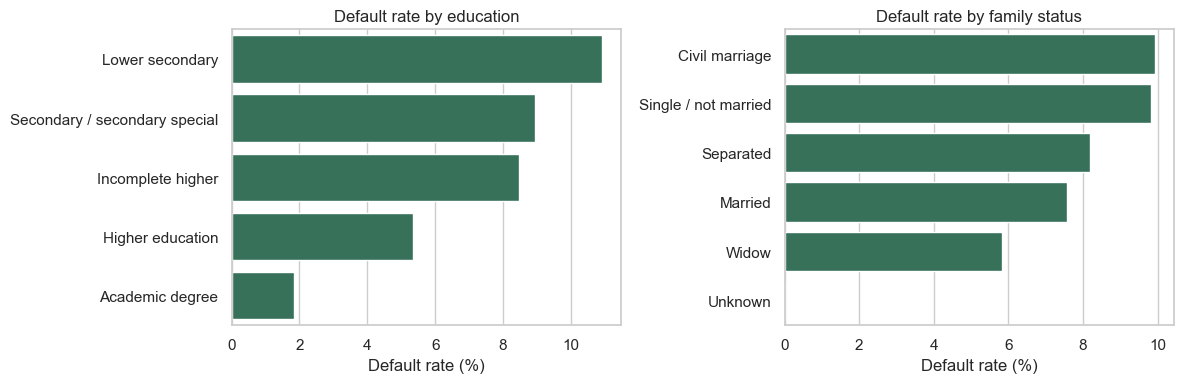

In [10]:
#Default rate by education and family status
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=by_education, y="name_education_type", x="default_rate_pct", ax=axes[0], color=ACCENT)
axes[0].set_title("Default rate by education")
axes[0].set_xlabel("Default rate (%)")
axes[0].set_ylabel("")

sns.barplot(data=by_family, y="name_family_status", x="default_rate_pct", ax=axes[1], color=ACCENT)
axes[1].set_title("Default rate by family status")
axes[1].set_xlabel("Default rate (%)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Finding:** default rates vary meaningfully across both education and
family status — these are candidate segmentation features, and as sense-check variables once the scorecard is built.

## 5. Repayment behavior — DPD distribution and PAR

In [12]:
dpd_dist = pd.read_sql("""
    SELECT dpd_bucket, count(*) AS n_instalments, sum(amt_instalment) AS total_amt
    FROM staging.stg_installments_payments
    GROUP BY dpd_bucket;
""", engine)

bucket_order = ["current", "1-30", "31-60", "61-90", "90+", "unpaid_or_pending"]
dpd_dist["dpd_bucket"] = pd.Categorical(dpd_dist["dpd_bucket"], categories=bucket_order, ordered=True)
dpd_dist = dpd_dist.sort_values("dpd_bucket")
dpd_dist

,dpd_bucket,n_instalments,total_amt
4,current,12455827,"215,620,078,393.53"
0,1-30,1108027,"16,081,478,680.95"
1,31-60,22477,"174,293,204.04"
2,61-90,3427,"12,669,590.38"
3,90+,12738,"48,584,498.40"
5,unpaid_or_pending,2905,"47,322,631.35"


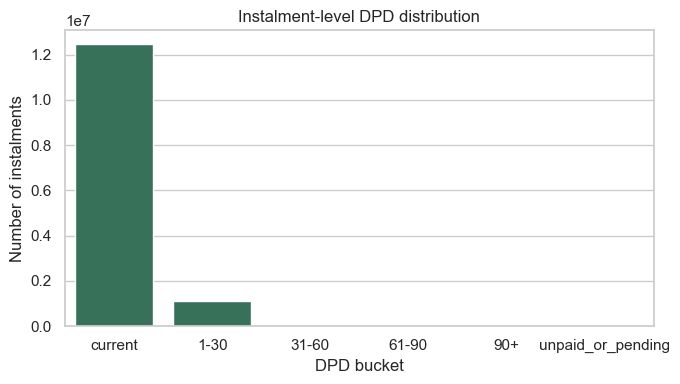

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=dpd_dist, x="dpd_bucket", y="n_instalments", ax=ax, color=ACCENT)
ax.set_xlabel("DPD bucket")
ax.set_ylabel("Number of instalments")
ax.set_title("Instalment-level DPD distribution")
plt.tight_layout()
plt.show()

As expected, the **current** bucket is dominating with a shrinking tail through the later buckets.

In [14]:
par_summary = pd.read_sql("""
    SELECT
        round(count(*) FILTER (WHERE ever_30_plus) * 100.0 / count(*), 2) AS par30_by_count,
        round(count(*) FILTER (WHERE ever_60_plus) * 100.0 / count(*), 2) AS par60_by_count,
        round(count(*) FILTER (WHERE ever_90_plus) * 100.0 / count(*), 2) AS par90_by_count
    FROM metrics.loan_level_dpd;
""", engine)
par_summary

,par30_by_count,par60_by_count,par90_by_count
0,2.32,1.02,0.83
